## CNN for Classification Using Pytorch

In [4]:
import torch
import torchvision
import cv2
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader

In [5]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 4060 Laptop GPU


In [13]:
image_dir = 'dataset/seg_train'
for label,class_dir in enumerate(os.listdir(image_dir)):
    print(label, class_dir)

0 buildings
1 forest
2 glacier
3 mountain
4 sea
5 street


### Loading the Dataset


In [43]:
class ImageDataset(Dataset):
    def __init__(self,image_dir,transform=None):
        self.image_dir=image_dir
        self.image_paths= []
        self.class_names={}
        self.labels=[]
        self.transform=transform
        for label,class_dir in enumerate(os.listdir(image_dir)):
            self.class_names[label]=class_dir
            class_path = os.path.join(image_dir,class_dir)
            for img_name in (os.listdir(class_path)):
                self.image_paths.append(os.path.join(class_path,img_name))
                self.labels.append(label)
    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self,idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert('RGB')
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image,label

In [ ]:
transform = torchvision.transforms.Compose([
    torchvision.transforms.Resize((128,128)),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean=[0.5,0.5,0.5],std=[0.5,0.5,0.5])])

In [69]:
train_image_dir = 'dataset/seg_train'
test_image_dir = 'dataset/seg_test'


In [70]:
train_image_data = ImageDataset(image_dir=train_image_dir,transform=transform)
test_image_data = ImageDataset(image_dir=test_image_dir,transform=transform)


In [71]:
train_data_loader = DataLoader(dataset=train_image_data,batch_size=32,shuffle=True)
test_data_loader = DataLoader(dataset=test_image_data,batch_size=32,shuffle=True)


In [72]:
for image,label in train_data_loader:
    print(image.shape,label.shape)
    break

torch.Size([32, 3, 150, 150]) torch.Size([32])


In [73]:
print(train_image_data.class_names)
print(test_image_data.class_names)

{0: 'buildings', 1: 'forest', 2: 'glacier', 3: 'mountain', 4: 'sea', 5: 'street'}
{0: 'buildings', 1: 'forest', 2: 'glacier', 3: 'mountain', 4: 'sea', 5: 'street'}


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


torch.Size([32, 3, 150, 150]) torch.Size([32])
(3, 150, 150)
street
(150, 150, 3)
5


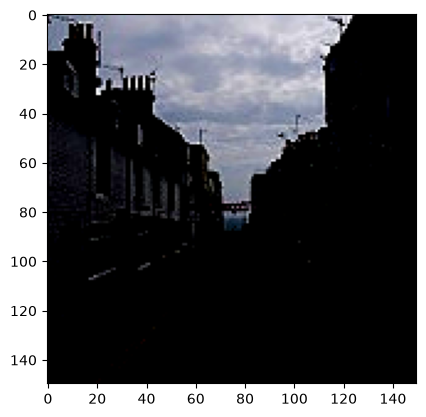

In [85]:
import matplotlib.pyplot as plt 
import numpy as np
for image,labels in train_data_loader:
    print(image.shape,labels.shape)
    img = image[0].numpy()
    print(img.shape)
    label = labels[0].item()
    print(train_image_data.class_names[label])
    img = np.transpose(img,(1,2,0))
    print(img.shape)
    print(label)
    plt.imshow(img)
    break

### Convolution Neural Network

In [86]:
import torch.nn as nn
import torch.optim as optim


In [87]:
class ImageClassifier(nn.Module):
    def __init__(self):
        pass
    def forward():
        pass